# **MLR**

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data =pd.read_csv(r"C:\Users\LENOVO\Downloads\advertising.csv")
data.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [4]:
data.shape

(200, 4)

In [5]:
data.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [6]:
# Define dependent(y) and independent variables(x)
x = data[['TV','Radio','Newspaper']] #Independent
y = data[['Sales']] # Target

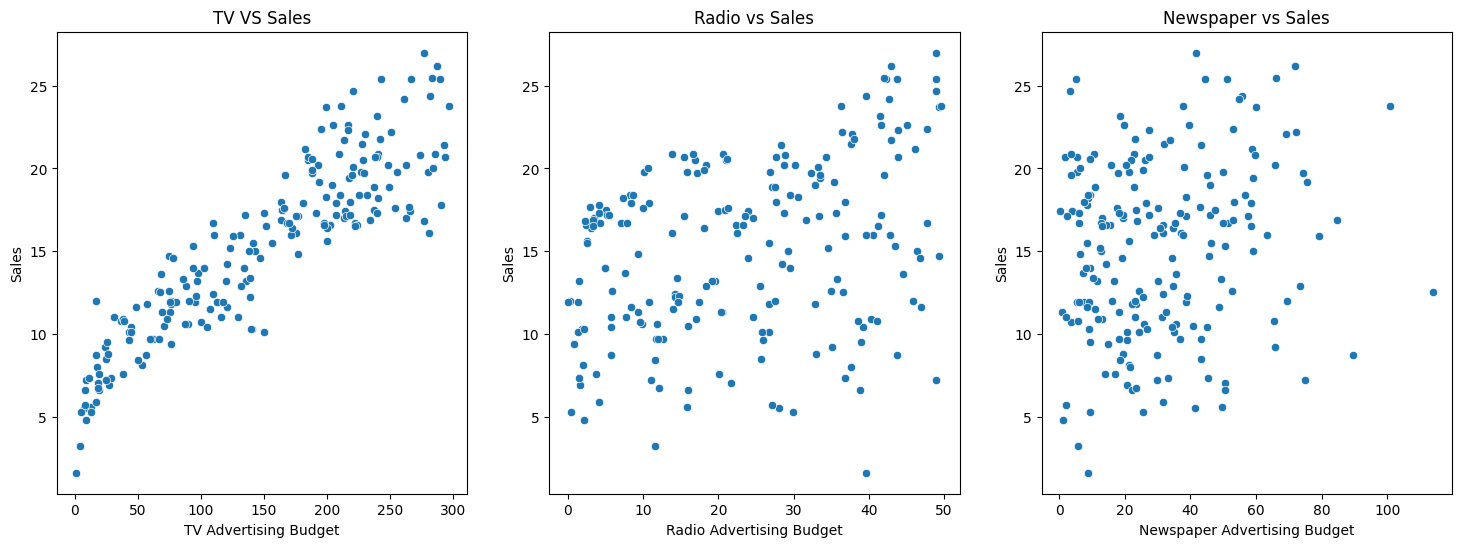

In [7]:
plt.figure(figsize=(18,6))
# Plotting the plot
plt.subplot(1,3,1)
sns.scatterplot(x=data['TV'],y=data['Sales'])
plt.title("TV VS Sales")
plt.xlabel('TV Advertising Budget')
plt.ylabel('Sales')

# Scatter plot for radio vs Sales
plt.subplot(1,3,2)
sns.scatterplot(x=data['Radio'],y=data['Sales'])
plt.title('Radio vs Sales')
plt.xlabel('Radio Advertising Budget')
plt.ylabel("Sales")

# Scatter plot for Newspaper vs Sales
plt.subplot(1,3,3)
sns.scatterplot(x=data['Newspaper'],y=data['Sales'])
plt.title('Newspaper vs Sales')
plt.xlabel('Newspaper Advertising Budget')
plt.ylabel("Sales")
plt.show()

In [8]:
# Inferance:
## Stronge Coorelation: Tv Vs Sales

In [9]:
# Check any predictor (x) is co-related to another predictors(x)
x.corr()
# if any highly correlated with other we will remove one to reduce cost

,TV,Radio,Newspaper
TV,1.000000,0.054809,0.056648
Radio,0.054809,1.000000,0.354104
Newspaper,0.056648,0.354104,1.000000


## **Compute the coorelation matrix**

                 TV     Radio  Newspaper
TV         1.000000  0.054809   0.056648
Radio      0.054809  1.000000   0.354104
Newspaper  0.056648  0.354104   1.000000


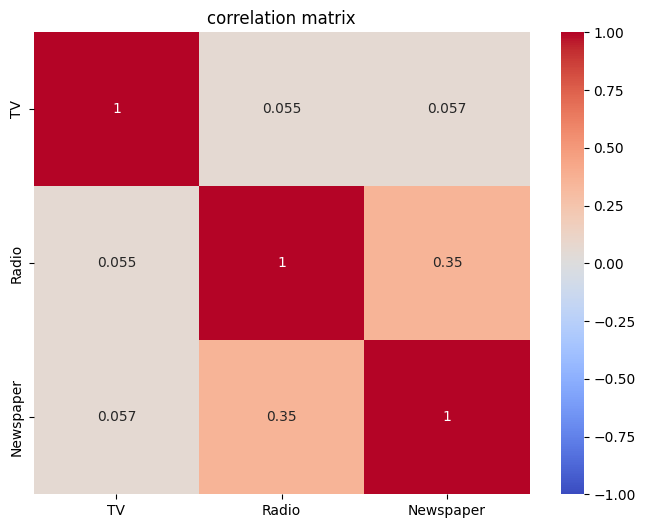

In [10]:
correlation_matrix = x.corr()

# Plot the correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',vmin=-1,vmax=1)
plt.title('correlation matrix')

# Display the correlation matrix
print(correlation_matrix)

In [11]:
# VIF Very important in MLR
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate the VIF for each feature
vif_data= pd.DataFrame()
vif_data['feature'] = x.columns
vif_data['VIF'] = [variance_inflation_factor(x.values,i) for i in range(x.shape[1])]
print("Varience Inflation Factor(VIF):")
print(vif_data)

Varience Inflation Factor(VIF):
     feature       VIF
0         TV  2.486772
1      Radio  3.285462
2  Newspaper  3.055245


## **Split the data into training and testing sets**

In [12]:
x_train ,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)

In [13]:
x_train.shape,y_train.shape

((140, 3), (140, 1))

In [14]:
x_test.shape ,y_test.shape

((60, 3), (60, 1))

In [15]:
x_train.head()

,TV,Radio,Newspaper
169,284.3,10.6,6.4
97,184.9,21.0,22.0
31,112.9,17.4,38.6
12,23.8,35.1,65.9
35,290.7,4.1,8.5


In [16]:
y_train.head()

,Sales
169,20.0
97,20.5
31,11.9
12,9.2
35,17.8


In [17]:
# Create and train the linear regression model
linear_model = LinearRegression()
linear_model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [18]:
# Make predictions
y_test_pred = linear_model.predict(x_test)

In [19]:
y_test.head()

,Sales
95,16.9
15,22.4
30,21.4
158,7.3
128,24.7


In [20]:
# Create DataFrame for testing data
y_test_pred.flatten()

array([17.15991908, 20.53369503, 23.68914396,  9.5191455 , 21.60736836,
       12.78101318, 21.08636345,  8.76054246, 17.11499951, 16.68789636,
        8.97584663,  8.57645026, 18.33212325,  8.17863567, 12.64605571,
       14.94486946,  8.34939536, 17.83858948, 11.12172174, 20.37740648,
       20.9483297 , 13.04035779, 11.01360656, 22.51142595,  9.40369784,
        7.98591291, 20.86943368, 13.77882255, 10.83407064,  8.00419229,
       15.88597618, 10.7027424 , 20.9521718 , 10.84679243, 21.50720813,
       21.07347295, 12.22673775, 22.85273767, 12.57698182,  6.54597206,
       11.93411853, 15.23490068, 10.07411153,  9.52159696, 17.11786382,
        7.28032677, 10.49404864, 15.24356754, 11.20742176, 11.78392665,
       14.01472163, 14.59884572, 10.82722434,  9.55839415,  9.03749681,
       12.51183313, 10.52551021, 25.01900824,  7.99334943, 15.73916263])

In [21]:
y_test.head()

,Sales
95,16.9
15,22.4
30,21.4
158,7.3
128,24.7


## **Model Evaluation Teacniques for Multiple Linear Regression(MLR)**
**Why Model Evaluation?.**
Model evaluation help us to measure how well our regression model; predicts the target variable<br>
Even if the model looks goods . we need metrices to asses accuaracy ,error and explanatory power.

## **R Square**

In [22]:
from sklearn.metrics import r2_score
import numpy as np

actual = [10,15,18]
pred = [12,14,16]

print('R Square:',r2_score(actual,pred))

R Square: 0.7244897959183674


**Interpretation:**<br>
R Square =0.72 The model explains 72% of the varience in the tareget variable.

## **RMSE (ROOT MEAN Squared Error)**

In [23]:
from sklearn.metrics import mean_squared_error
import numpy as np

actual = [10,15,18]
pred = [ 12,14,16]
rmse = np.sqrt(mean_squared_error(actual,pred))
print('RMSE: ',round(rmse,3))

RMSE:  1.732


No calculate RMSE: 

In [24]:
# Mean Absolute Error
from sklearn.metrics import mean_absolute_error
actual = [10,15,18]
pred = [12,14,16]

mae = mean_absolute_error(actual,pred)
print("MAE: ",round(mae,2))

MAE:  1.67


**Interpretion MAE = 1.67 --> On average are 1.67 units off from actual values.**

## **MAPE**

In [25]:
actual = [10,15,18]
pred = np.array([12,14,16])

mape = np.mean(np.abs((actual-pred)/actual))*100
print('MAPE: ',round(mape,2),'%')

MAPE:  12.59 %


## **Evaluate the Model**

In [26]:
mse_test = mean_squared_error(actual,pred)
r2_test= r2_score(actual,pred)
print(f"Multiple Regression- Testing MSE:{mse_test},Testing R2: {r2_test}")

Multiple Regression- Testing MSE:3.0,Testing R2: 0.7244897959183674


## **Residual Value:**
A residual is a differance between the actual value and predicted value.

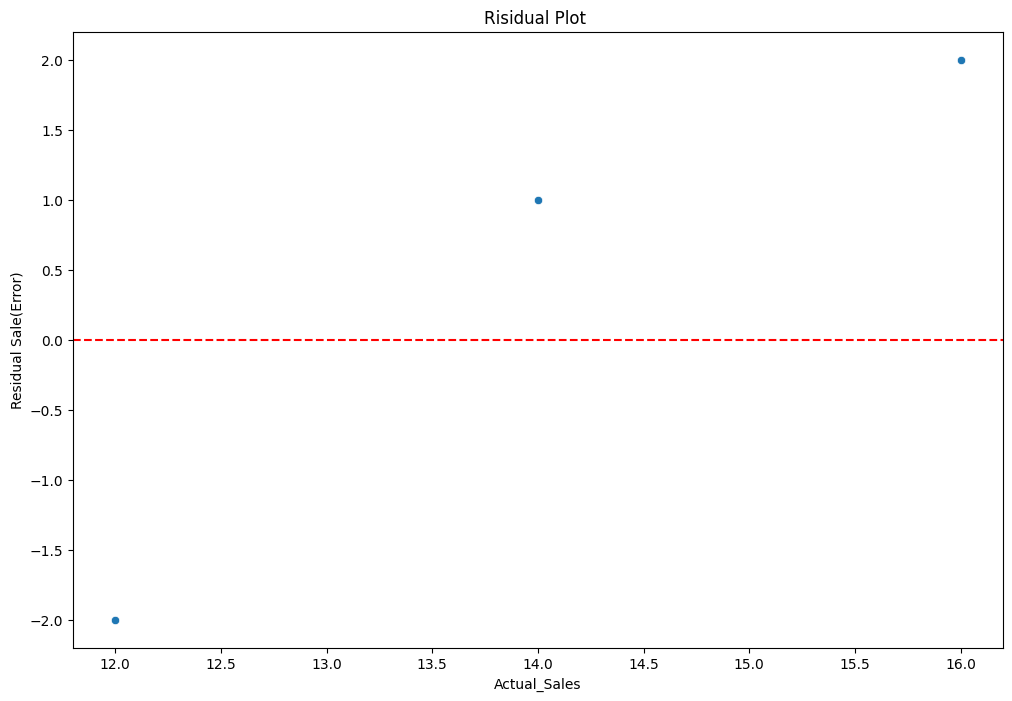

In [27]:
# Residuals

residual_tests = actual-pred

# Plot residuals
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,8))
sns.scatterplot(x=pred,y=residual_tests)
plt.axhline(0,color='r',linestyle ='--')
plt.xlabel("Actual_Sales")
plt.ylabel("Residual Sale(Error)")
plt.title("Risidual Plot ")
plt.show()

In [28]:
# There is no clear pattern , it is good.

In [29]:
# How to fix!!!
## Add polynomial Terns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
poly_model = make_pipeline(PolynomialFeatures(degree=2),LinearRegression())
poly_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('polynomialfeatures', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06


In [30]:
## apply features transformation
data['TV_Radio'] = data['TV'] +data["Radio"]
data.head()

,TV,Radio,Newspaper,Sales,TV_Radio
0,230.1,37.8,69.2,22.1,267.9
1,44.5,39.3,45.1,10.4,83.8
2,17.2,45.9,69.3,12.0,63.1
3,151.5,41.3,58.5,16.5,192.8
4,180.8,10.8,58.4,17.9,191.6


In [31]:
# display statistics of model , p Value for each feature and share your inference.

In [32]:
import statsmodels.api as sm

#Add a constant to the model (intercept)
x_train_const = sm.add_constant(x_train)

#Fit the ols model with intercept
ols_model = sm.OLS(y_train,x_train_const).fit()

#Print the summary to get p-values
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.892
Model:                            OLS   Adj. R-squared:                  0.890
Method:                 Least Squares   F-statistic:                     374.3
Date:                Mon, 09 Mar 2026   Prob (F-statistic):           1.69e-65
Time:                        14:01:47   Log-Likelihood:                -271.70
No. Observations:                 140   AIC:                             551.4
Df Residuals:                     136   BIC:                             563.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.7438      0.400     11.863      0.0

In [33]:
# Quiz : What is your inferance about p value for each feature ?
## Since for newspaper p value > then 0.5 we accept the null hypothesis.
### Newspaper is not playing significant role,We remove this feature.

## **After removing newspaper from dataset, since its p value is not significant**

In [34]:
import numpy as np
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
import matplotlib.pyplot as plt
import  seaborn as sns


In [35]:
data1 =  pd.read_csv(r"C:\Users\LENOVO\Downloads\advertising.csv")
data1.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [36]:
# Difine the independent variable (x) and the dependent variable (y)
X1 = data1[['TV',"Radio"]]
Y1 = data1[['Sales']]

# Split the data into training and testing sets
X_train1,X_test1,Y_train1,Y_test1 = train_test_split(X1,Y1,test_size=0.2,random_state=42)

In [37]:
# Create and train linear regression model.
linear_model = LinearRegression()
linear_model.fit(X_train1,Y_train1)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [38]:
# Make predictions
Y_test1_pred1 = linear_model.predict(X_test1)

In [39]:
# Evaluate the model
mse_test1 = mean_squared_error(Y_test1,Y_test1_pred1)
r2_test1 = r2_score(Y_test1,Y_test1_pred1)

print(f"Multiple Linear Regression - Testing MSE: {mse_test1}, Testing R2: {r2_test1}")

Multiple Linear Regression - Testing MSE: 2.846616122131541, Testing R2: 0.9078797802624651


In [40]:
import statsmodels.api as sm
# Add a constant to the model (intercept)
X_train_const1 = sm.add_constant(X_train1)

# Fit the OLS model with intercept
ols_model1 = sm.OLS(Y_train1,X_train_const1).fit()

# print the summary to p - values 
print(ols_model1.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                     705.7
Date:                Mon, 09 Mar 2026   Prob (F-statistic):           3.43e-79
Time:                        14:01:47   Log-Likelihood:                -305.98
No. Observations:                 160   AIC:                             618.0
Df Residuals:                     157   BIC:                             627.2
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.7914      0.328     14.606      0.0

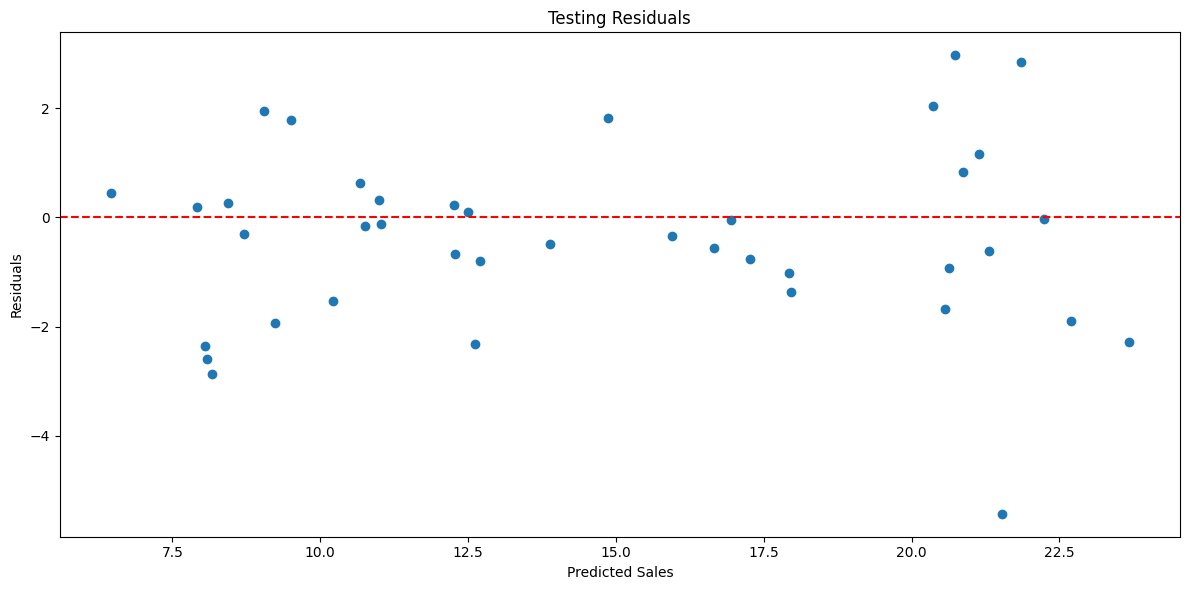

In [41]:
# Residual 
residual1 = Y_test1 - Y_test1_pred1

# Plot residuals
plt.figure(figsize=(12,6))
plt.scatter(x=Y_test1_pred1,y=residual1)
plt.axhline(0,color = 'r',linestyle ='--')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')
plt.title('Testing Residuals')

plt.tight_layout()
plt.show()